# CSA47 – Deep Learning | Assignment 2 (CO2)
## Deep Feed-Forward and Convolutional Network Design – Smart Agriculture & Crop Disease Detection

**Name:** SOORIYAVEL B **Reg. No.:** 192324090

This notebook contains the complete solution (theory, calculations, code and outputs) for Tasks 1–12.
Only `numpy`, `matplotlib`, `scikit-learn` and `pandas` are required. Keras/PyTorch reference code for the
full-scale model is given as text in Task 12.

In [1]:
import numpy as np, time, os
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)
os.makedirs('figs', exist_ok=True)
np.set_printoptions(precision=4, suppress=True)
print('Setup complete')

Setup complete


## TASK 1 – Deep Feed-Forward Network Architecture (5 Marks)

**a) Architecture.** Inputs: rainfall, temperature, soil moisture, fertilizer quantity → 4 input neurons.
Hidden layers: 8 and 4 neurons. Output: one neuron (continuous crop yield – regression, linear activation).

| Layer | Neurons | Activation |
|---|---|---|
| Input | 4 (x1..x4) | – |
| Hidden 1 | 8 | ReLU |
| Hidden 2 | 4 | ReLU |
| Output | 1 | Linear (identity) |

**b) Parameter dimensions** (column-vector convention, `z = W a + b`):

| Parameter | Shape | Count |
|---|---|---|
| W1, b1 | 8×4, 8×1 | 32 + 8 |
| W2, b2 | 4×8, 4×1 | 32 + 4 |
| W3, b3 | 1×4, 1×1 | 4 + 1 |
| **Total** | | **81** |

**c) Forward propagation.**
- `z1 = W1 x + b1`,  `a1 = ReLU(z1)`   (8×1)
- `z2 = W2 a1 + b2`, `a2 = ReLU(z2)`   (4×1)
- `ŷ  = W3 a2 + b3`                    (1×1, linear output)

Each layer computes a weighted sum, adds a bias and applies a non-linearity; the output is the predicted yield.

In [2]:
def relu(z): return np.maximum(0, z)

layer_sizes = [4, 8, 4, 1]
rng = np.random.default_rng(0)
params = {}
for i in range(1, len(layer_sizes)):
    params[f'W{i}'] = rng.normal(0, np.sqrt(2/layer_sizes[i-1]), (layer_sizes[i], layer_sizes[i-1]))
    params[f'b{i}'] = np.zeros((layer_sizes[i], 1))

total = 0
for k, v in params.items():
    print(f'{k}: shape {v.shape}, count {v.size}'); total += v.size
print('Total trainable parameters =', total)

# one normalized sample: rainfall, temperature, soil moisture, fertilizer
x = np.array([[0.6], [0.8], [0.5], [0.7]])
z1 = params['W1'] @ x + params['b1']; a1 = relu(z1)
z2 = params['W2'] @ a1 + params['b2']; a2 = relu(z2)
y_hat = params['W3'] @ a2 + params['b3']
print('\nz1', z1.shape, ' a1', a1.shape)
print('z2', z2.shape, ' a2', a2.shape)
print('Predicted (untrained) yield =', y_hat.item())

W1: shape (8, 4), count 32
b1: shape (8, 1), count 8
W2: shape (4, 8), count 32
b2: shape (4, 1), count 4
W3: shape (1, 4), count 4
b3: shape (1, 1), count 1
Total trainable parameters = 81

z1 (8, 1)  a1 (8, 1)
z2 (4, 1)  a2 (4, 1)
Predicted (untrained) yield = 1.108022042306721


## TASK 2 – Forward Propagation and Activation Functions (2 Marks)

Inputs (0.6, 0.8, 0.5), weights (0.4, 0.3, 0.2), bias 0.1.

`z = 0.6(0.4) + 0.8(0.3) + 0.5(0.2) + 0.1 = 0.24 + 0.24 + 0.10 + 0.10 = 0.68`

`ReLU(0.68) = max(0, 0.68) = 0.68`

**Interpretation:** z is positive, so the neuron is *active* and passes its value unchanged to the next layer.
Had z been negative, ReLU would output 0 (neuron "switched off").

In [3]:
x = np.array([0.6, 0.8, 0.5]); w = np.array([0.4, 0.3, 0.2]); b = 0.1
z = np.dot(w, x) + b
print('Weighted sum z =', round(z, 4))
print('ReLU(z)        =', round(max(0, z), 4))

Weighted sum z = 0.68
ReLU(z)        = 0.68


## TASK 3 – Gradient-Based Learning and Loss Calculation (6 Marks)

**a)** A loss function turns "how wrong is the prediction" into a single differentiable number. Without it there is
nothing to minimise and no gradient to guide the weight updates. For regression, **Mean Squared Error (MSE)** /
squared error is suitable: it is smooth, differentiable, penalises large errors heavily and has a convex form in ŷ.

**b)** `L = (y − ŷ)² = (50 − 42)² = 8² = 64`

**c)** The loss of 64 (RMSE-equivalent error of 8 units, i.e. 16 % of the true yield) shows the network under-predicts
significantly; a perfect prediction gives L = 0, so the weights need adjusting.

**d)** Gradient-based learning: (1) forward pass → ŷ; (2) compute L; (3) back-propagate to get ∂L/∂θ for every parameter;
(4) update `θ ← θ − η ∂L/∂θ`; repeat over many iterations so the loss decreases. Here ∂L/∂ŷ = −2(y−ŷ) = −16, which says
*increasing* ŷ reduces the loss.

In [4]:
y, y_pred = 50, 42
loss = (y - y_pred)**2
grad = -2*(y - y_pred)
print('Squared error loss L =', loss)
print('dL/dy_hat            =', grad)

Squared error loss L = 64
dL/dy_hat            = -16


## TASK 4 – Gradient Descent and Weight Update (4 Marks)

**a)** `w_new = w − η·∂L/∂w = 0.5 − 0.1 × 0.8 = 0.5 − 0.08 = 0.42`

**b)** The gradient points in the direction of steepest *increase* of the loss. To reduce loss we move opposite to it.
A positive gradient means increasing w raises the loss, so w must decrease.

**c)** *Very small η:* tiny steps, very slow convergence, may stall on plateaus/get stuck in poor local regions and
wastes compute. *Very large η:* overshoots the minimum, loss oscillates or diverges (can become NaN). A good η (often with decay) gives fast, stable convergence.

Updated weight = 0.42


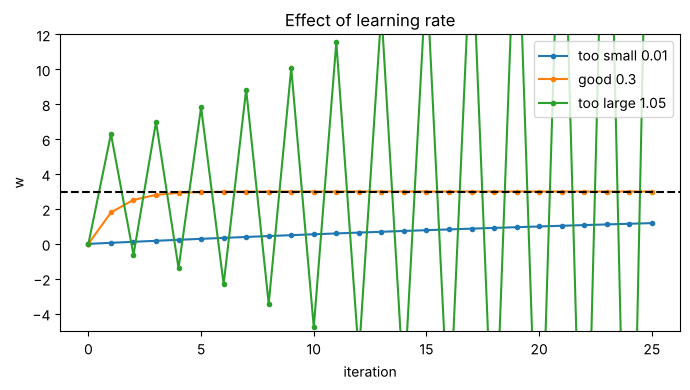

In [5]:
w, g, lr = 0.5, 0.8, 0.1
print('Updated weight =', round(w - lr*g, 4))

# learning-rate effect on minimising f(w) = (w-3)^2
def descend(lr, steps=25, w0=0.0):
    w, hist = w0, [w0]
    for _ in range(steps):
        w = w - lr*2*(w-3); hist.append(w)
    return hist
plt.figure(figsize=(7,4))
for lr_, lab in [(0.01,'too small 0.01'),(0.3,'good 0.3'),(1.05,'too large 1.05')]:
    plt.plot(descend(lr_), marker='o', ms=3, label=lab)
plt.axhline(3, ls='--', c='k'); plt.ylim(-5, 12); plt.xlabel('iteration'); plt.ylabel('w')
plt.title('Effect of learning rate'); plt.legend(); plt.tight_layout()
plt.savefig('figs/task4_lr.png', dpi=110); plt.show()

## TASK 5 – Back-Propagation Through Multiple Layers (3 Marks)

**a)** After the forward pass computes the loss, backpropagation sends the error backwards from output to input.
Each weight's gradient measures how much a small change in that weight would change the loss, i.e. its *contribution to the error*.

**b)** The loss depends on early weights only through a chain of intermediate functions
(W1 → a1 → a2 → ŷ → L). The chain rule multiplies local derivatives along this path:

`∂L/∂W1 = ∂L/∂ŷ · ∂ŷ/∂a2 · ∂a2/∂z2 · ∂z2/∂a1 · ∂a1/∂z1 · ∂z1/∂W1`

Backprop reuses the shared terms (δ values) layer by layer, so all gradients are computed in one backward sweep.

**c)** Each weight is updated with `W ← W − η ∂L/∂W` (and similarly for biases).

The code below implements backpropagation for the 4-8-4-1 network and **verifies it against numerical gradients**.

In [6]:
def init(sizes, seed=1):
    r = np.random.default_rng(seed); P = {}
    for i in range(1, len(sizes)):
        P[f'W{i}'] = r.normal(0, np.sqrt(2/sizes[i-1]), (sizes[i], sizes[i-1]))
        P[f'b{i}'] = np.zeros((sizes[i], 1))
    return P

def forward(P, X):                      # X: (features, samples)
    Z1 = P['W1']@X + P['b1'];  A1 = relu(Z1)
    Z2 = P['W2']@A1 + P['b2']; A2 = relu(Z2)
    Y  = P['W3']@A2 + P['b3']
    return Y, (X, Z1, A1, Z2, A2)

def mse(Y, T): return np.mean((Y-T)**2)

def backward(P, cache, Y, T):
    X, Z1, A1, Z2, A2 = cache; m = X.shape[1]
    dY  = 2*(Y-T)/m
    G = {'W3': dY@A2.T, 'b3': dY.sum(1, keepdims=True)}
    dA2 = P['W3'].T@dY;  dZ2 = dA2*(Z2>0)
    G['W2'] = dZ2@A1.T;  G['b2'] = dZ2.sum(1, keepdims=True)
    dA1 = P['W2'].T@dZ2; dZ1 = dA1*(Z1>0)
    G['W1'] = dZ1@X.T;   G['b1'] = dZ1.sum(1, keepdims=True)
    return G

# gradient check
P = init([4,8,4,1]); Xc = np.random.rand(4,5); Tc = np.random.rand(1,5)*10
Y, cache = forward(P, Xc); G = backward(P, cache, Y, Tc)
eps = 1e-6; worst = 0
for k in P:
    num = np.zeros_like(P[k])
    for idx in np.ndindex(*P[k].shape):
        old = P[k][idx]
        P[k][idx] = old+eps; lp = mse(forward(P,Xc)[0], Tc)
        P[k][idx] = old-eps; lm = mse(forward(P,Xc)[0], Tc)
        P[k][idx] = old; num[idx] = (lp-lm)/(2*eps)
    worst = max(worst, np.max(np.abs(num-G[k])))
print('Max |analytic - numerical| gradient difference =', worst)
print('Backprop verified' if worst < 1e-5 else 'Mismatch!')

Max |analytic - numerical| gradient difference = 3.11140763153972e-09
Backprop verified


## TASK 6 – Activation Functions and Vanishing/Exploding Gradients (3 Marks)

**a)** Backprop multiplies one activation derivative per layer. Sigmoid's derivative is at most 0.25 and tanh's at most 1
(and < 1 away from 0); saturated neurons give derivatives ≈ 0. After n layers the gradient shrinks roughly like (0.25)ⁿ,
so early layers barely learn → *vanishing gradients*. (If weights/derivatives are repeatedly > 1 the product blows up → *exploding gradients*.)

**b)**

| | Sigmoid | tanh | ReLU |
|---|---|---|---|
| Range | (0,1) | (−1,1) | [0,∞) |
| Max derivative | 0.25 | 1 | 1 |
| Zero-centred | No | Yes | No |
| Saturation | Both ends | Both ends | Only for z<0 (dead neurons) |
| Cost | exp – costly | exp – costly | very cheap |
| Hidden-layer use | Avoid | Acceptable (shallow) | Default |

**c)** Non-saturating activations (ReLU, Leaky ReLU, GELU) keep gradient ≈ 1 for active units, enabling faster and deeper training;
combined with He initialisation, batch-norm, residual connections and gradient clipping they mitigate vanishing/exploding gradients.

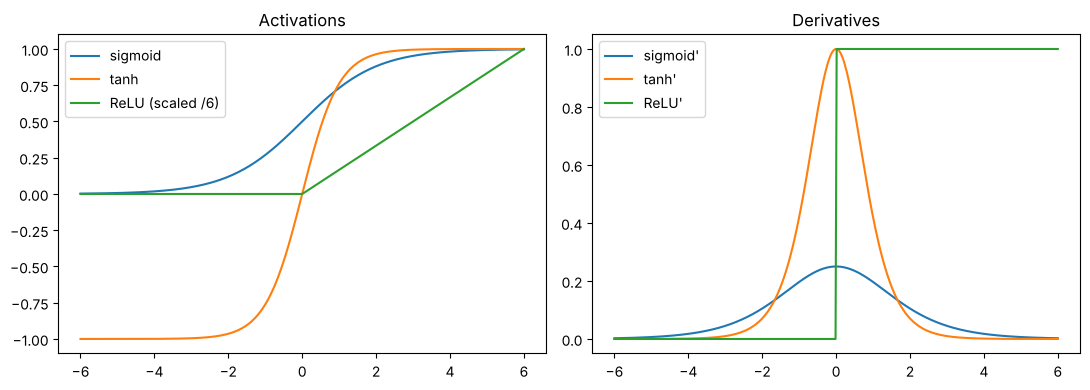

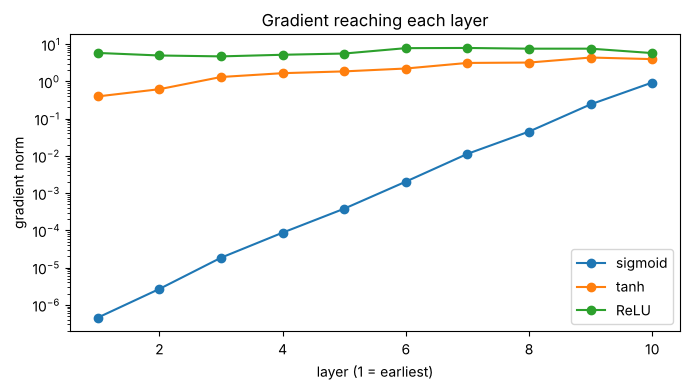

sigmoid  gradient at layer 1 = 4.53e-07, at layer 10 = 9.35e-01
tanh     gradient at layer 1 = 3.95e-01, at layer 10 = 3.97e+00
ReLU     gradient at layer 1 = 5.82e+00, at layer 10 = 5.76e+00


In [7]:
z = np.linspace(-6, 6, 400)
sig = 1/(1+np.exp(-z)); d_sig = sig*(1-sig)
d_tanh = 1-np.tanh(z)**2; d_relu = (z>0).astype(float)
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(z, sig, label='sigmoid'); ax[0].plot(z, np.tanh(z), label='tanh'); ax[0].plot(z, np.maximum(0,z)/6, label='ReLU (scaled /6)')
ax[0].set_title('Activations'); ax[0].legend()
ax[1].plot(z, d_sig, label='sigmoid\''); ax[1].plot(z, d_tanh, label='tanh\''); ax[1].plot(z, d_relu, label='ReLU\'')
ax[1].set_title('Derivatives'); ax[1].legend()
plt.tight_layout(); plt.savefig('figs/task6_act.png', dpi=110); plt.show()

# gradient reaching each layer of a 10-layer net (width 20) for 3 activations
def grad_norms(act, dact, L=10, width=20, seed=0, scale=None):
    r = np.random.default_rng(seed); a = r.normal(size=(width,1)); Ws=[]; Zs=[]
    for _ in range(L):
        std = scale if scale else np.sqrt(2/width)
        W = r.normal(0, std, (width,width)); z_ = W@a; Ws.append(W); Zs.append(z_); a = act(z_)
    g = np.ones((width,1)); norms=[]
    for W, z_ in zip(reversed(Ws), reversed(Zs)):
        g = W.T@(g*dact(z_)); norms.append(np.linalg.norm(g))
    return norms[::-1]
res = {
 'sigmoid': grad_norms(lambda z:1/(1+np.exp(-z)), lambda z:(1/(1+np.exp(-z)))*(1-1/(1+np.exp(-z))), scale=0.2),
 'tanh'   : grad_norms(np.tanh, lambda z:1-np.tanh(z)**2, scale=0.2),
 'ReLU'   : grad_norms(relu, lambda z:(z>0)*1.0),
}
plt.figure(figsize=(7,4))
for k,v in res.items(): plt.semilogy(range(1,11), v, marker='o', label=k)
plt.xlabel('layer (1 = earliest)'); plt.ylabel('gradient norm'); plt.title('Gradient reaching each layer'); plt.legend(); plt.tight_layout()
plt.savefig('figs/task6_grad.png', dpi=110); plt.show()
for k,v in res.items(): print(f'{k:8s} gradient at layer 1 = {v[0]:.2e}, at layer 10 = {v[-1]:.2e}')

## TASK 7 – Back-Propagation and Optimization Strategy (4 Marks)

**a)** Learning rate η sets the step size. Too small → slow, steady loss decrease. Too large → big jumps, oscillation/divergence.

**b)** One iteration: (1) forward pass on a mini-batch → predictions; (2) compute loss; (3) **backpropagation** computes ∂L/∂θ for every parameter;
(4) **gradient descent** applies θ ← θ − η∇θL. Backprop *finds* the gradients, gradient descent *uses* them.

**c)** *Slow decrease:* increase η (or use Adam/momentum), normalise inputs, use batch-norm/better initialisation, ReLU.
*Fast but fluctuating:* reduce η or use a decay schedule, increase batch size, use momentum/Adam, gradient clipping.

**d)** The loss curve (training and validation) reveals under-fitting, over-fitting, divergence, oscillation or plateaus, and tells when to stop, tune η or regularise.

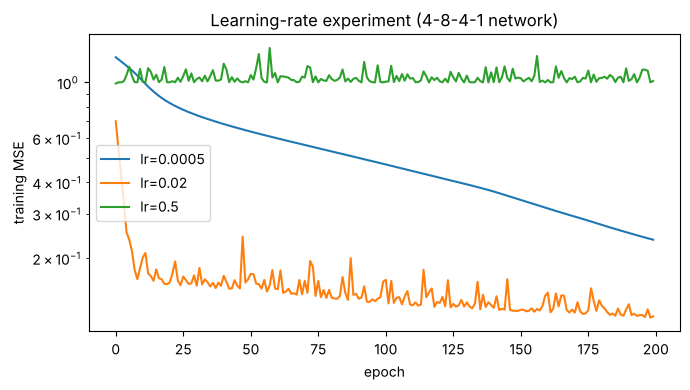

lr=0.0005  final MSE = 0.2368   (epoch-1 MSE = 1.259)
lr=0.02    final MSE = 0.1173   (epoch-1 MSE = 0.700)
lr=0.5     final MSE = 1.0134   (epoch-1 MSE = 0.990)


In [8]:
# Synthetic crop-yield data (features already normalised to [0,1])
rng = np.random.default_rng(7)
N = 600
rain = rng.uniform(0,1,N); temp = rng.uniform(0,1,N); soil = rng.uniform(0,1,N); fert = rng.uniform(0,1,N)
yield_ = 20 + 30*rain + 10*np.sin(3*temp) + 25*soil + 15*fert*(1-fert)*4 + rng.normal(0,1.0,N)
X = np.vstack([rain,temp,soil,fert]); T = ((yield_-yield_.mean())/yield_.std()).reshape(1,-1)

def train(lr, epochs=200, batch=32, seed=3):
    P = init([4,8,4,1], seed); losses=[]
    for ep in range(epochs):
        idx = np.random.default_rng(ep).permutation(N)
        for s in range(0, N, batch):
            b = idx[s:s+batch]
            Y, c = forward(P, X[:,b]); G = backward(P, c, Y, T[:,b])
            for k in P: P[k] -= lr*G[k]
        losses.append(mse(forward(P,X)[0], T))
    return losses
curves = {lr: train(lr) for lr in [0.0005, 0.02, 0.5]}
plt.figure(figsize=(7,4))
for lr, l in curves.items(): plt.plot(l, label=f'lr={lr}')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('training MSE'); plt.legend(); plt.title('Learning-rate experiment (4-8-4-1 network)')
plt.tight_layout(); plt.savefig('figs/task7_lr.png', dpi=110); plt.show()
for lr, l in curves.items(): print(f'lr={lr:<7} final MSE = {l[-1]:.4f}   (epoch-1 MSE = {l[0]:.3f})')

## TASK 8 – Regularization and Overfitting Control (4 Marks)

**a)** 99 % training vs 78 % validation accuracy – a 21-point gap – indicates **overfitting** (high variance): the model memorised
the training set (including noise) and does not generalise.

**b)** *L1* adds λΣ|w| – drives many weights exactly to zero → sparse model / feature selection. *L2* adds λΣw² – shrinks all weights smoothly
(weight decay) → simpler, smoother function. Both penalise large weights and thus limit effective model complexity.

**c)** `L_reg = (1/m) Σ (yᵢ − ŷᵢ)² + λ Σ_l ‖W_l‖²_F` (often with ½ or 1/2m factor). λ ≥ 0 controls strength: λ=0 → no regularization (overfit); very large λ → weights ≈ 0 (underfit); choose λ by validation.
Gradient update becomes `w ← w − η(∂L/∂w + 2λw)`.

**d)** Dropout randomly zeroes a fraction p of hidden units each training step (scaling the rest by 1/(1−p)). Neurons cannot co-adapt, the network behaves like an ensemble of sub-networks, reducing variance. Dropout is switched off at test time.

In [9]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
import warnings; warnings.filterwarnings('ignore')

# synthetic 'crop category' task with noisy labels -> easy to overfit
Xc, yc = make_classification(n_samples=300, n_features=20, n_informative=6, n_redundant=4,
                             n_classes=3, flip_y=0.03, class_sep=1.2, random_state=0)
Xtr, Xva, ytr, yva = train_test_split(Xc, yc, test_size=0.5, random_state=0)
sc = StandardScaler().fit(Xtr); Xtr, Xva = sc.transform(Xtr), sc.transform(Xva)

print('alpha(L2)   train_acc   val_acc')
for a in [0.0, 0.1, 1.0, 3.0, 10.0, 30.0]:
    m = MLPClassifier(hidden_layer_sizes=(128,128), alpha=a, max_iter=800, random_state=0).fit(Xtr, ytr)
    print(f'{a:<10} {m.score(Xtr,ytr):9.3f} {m.score(Xva,yva):9.3f}')

# --- Dropout demonstration (inverted dropout)
a = np.ones((1,10)); p = 0.5
mask = (np.random.default_rng(1).random(a.shape) > p) / (1-p)
print('\nDropout mask (p=0.5, inverted):', mask)
print('Activations after dropout     :', a*mask)
print('Mean activation preserved ->', (a*mask).mean())

# --- L2-regularised loss function
def l2_loss(y, yhat, Ws, lam):
    return np.mean((y-yhat)**2) + lam*sum(np.sum(W**2) for W in Ws)
print('\nL2 loss example (lam=0.01):', round(l2_loss(np.array([50.]), np.array([42.]), [np.array([[0.5,-0.3],[0.2,0.8]])], 0.01), 4))

alpha(L2)   train_acc   val_acc


0.0            1.000     0.693


0.1            1.000     0.687


1.0            1.000     0.713


3.0            1.000     0.747


10.0           0.947     0.773


30.0           0.353     0.320

Dropout mask (p=0.5, inverted): [[2. 2. 0. 2. 0. 0. 2. 0. 2. 0.]]
Activations after dropout     : [[2. 2. 0. 2. 0. 0. 2. 0. 2. 0.]]
Mean activation preserved -> 1.0

L2 loss example (lam=0.01): 64.0102


## TASK 9 – Convolution Operation and Feature Extraction (3 Marks)

**a)** Convolutional layers exploit the structure of images: **local connectivity** (spots/edges are local patterns), **weight sharing** (same filter slides everywhere → far fewer parameters), and **translation equivariance** (a spot is detected wherever it appears). They build up edge → texture → lesion features automatically.

**b)** Example: 5×5 image with a vertical-edge (Sobel-like) 3×3 filter, stride 1, no padding → 3×3 output. Large magnitude = strong vertical edge (e.g. boundary of a disease spot); ≈0 = uniform region.

**c)** *Filters* – small learnable weight grids, each detects one feature; *stride* – step of the filter (larger → smaller output); *padding* – border zeros keeping spatial size ('same') or none ('valid'). Output size `⌊(n + 2p − f)/s⌋ + 1`.

Image:
 [[10. 10. 10.  0.  0.]
 [10. 10. 10.  0.  0.]
 [10. 10. 10.  0.  0.]
 [10. 10. 10.  0.  0.]
 [10. 10. 10.  0.  0.]]
Filter:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

First output value (top-left): sum(patch*filter) = 0.0

Convolution (stride 1, pad 0) -> (3, 3)
[[ 0. 30. 30.]
 [ 0. 30. 30.]
 [ 0. 30. 30.]]

Stride 2, pad 0 -> (2, 2)
[[ 0. 30.]
 [ 0. 30.]]

Stride 1, pad 1 ("same") -> (5, 5)
[[-20.   0.  20.  20.   0.]
 [-30.   0.  30.  30.   0.]
 [-30.   0.  30.  30.   0.]
 [-30.   0.  30.  30.   0.]
 [-20.   0.  20.  20.   0.]]


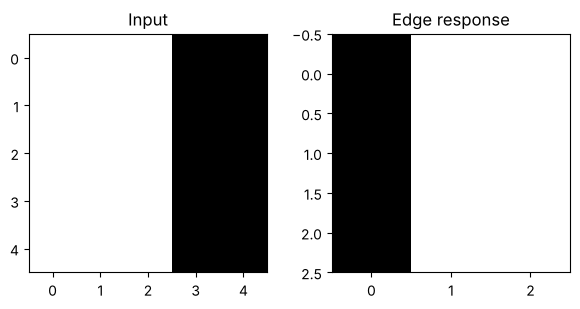

In [10]:
img = np.array([[10,10,10, 0, 0],
                [10,10,10, 0, 0],
                [10,10,10, 0, 0],
                [10,10,10, 0, 0],
                [10,10,10, 0, 0]], dtype=float)
filt = np.array([[1,0,-1],[1,0,-1],[1,0,-1]], dtype=float)

def conv2d(x, k, stride=1, pad=0):
    if pad: x = np.pad(x, pad)
    f = k.shape[0]; n = (x.shape[0]-f)//stride + 1
    out = np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            out[i,j] = np.sum(x[i*stride:i*stride+f, j*stride:j*stride+f]*k)
    return out

print('Image:\n', img); print('Filter:\n', filt)
print('\nFirst output value (top-left): sum(patch*filter) =', np.sum(img[:3,:3]*filt))
print('\nConvolution (stride 1, pad 0) ->', conv2d(img,filt).shape); print(conv2d(img,filt))
print('\nStride 2, pad 0 ->', conv2d(img,filt,2).shape); print(conv2d(img,filt,2))
print('\nStride 1, pad 1 ("same") ->', conv2d(img,filt,1,1).shape); print(conv2d(img,filt,1,1))
fig, ax = plt.subplots(1,2, figsize=(6,3)); ax[0].imshow(img, cmap='gray'); ax[0].set_title('Input')
ax[1].imshow(conv2d(img,filt), cmap='gray'); ax[1].set_title('Edge response'); plt.tight_layout()
plt.savefig('figs/task9_conv.png', dpi=110); plt.show()

## TASK 10 – CNN Architecture and Pooling (4 Marks)

**a) Components.** *Input image* – raw pixels (H×W×3). *Convolution* – learnable filters extract local features. *ReLU* – non-linearity, sparse activations, avoids vanishing gradient.
*Pooling* – down-samples feature maps, gives small translation invariance. *Fully connected layer* – combines all high-level features. *Output* – softmax/sigmoid probability of healthy vs diseased.

**b)** Pooling slides a window (e.g. 2×2, stride 2) and keeps the max (or mean) – output size `⌊(n − f)/s⌋ + 1`, so a 2×2/2 pool halves height and width (75 % fewer activations).

**c)** Larger filters → larger receptive field but more parameters, smaller output (without padding). Larger stride → smaller feature maps, less computation but possible information loss. More filters → more channels (depth) = more feature types, more parameters/memory.

**d)** Early layers learn edges/colour blobs; middle layers combine them into textures/spots; deeper layers combine into lesion patterns / whole-leaf structure. Receptive field grows with depth.

In [11]:
def maxpool(x, f=2, s=2):
    n = (x.shape[0]-f)//s + 1
    return np.array([[x[i*s:i*s+f, j*s:j*s+f].max() for j in range(n)] for i in range(n)])
fm = np.array([[1,3,2,1],[4,6,5,2],[7,2,9,0],[1,8,3,4]], dtype=float)
print('Feature map:\n', fm); print('\n2x2 max pool, stride 2:\n', maxpool(fm))

# Shape / parameter table for the proposed CNN on a 64x64x3 leaf image
def conv_out(n,f,s=1,p=0): return (n+2*p-f)//s+1
H=64; C=3; rows=[]; total=0
H1=conv_out(H,3); p1=8*(3*3*C)+8;  rows.append(('Conv1 3x3, 8 filters', (H1,H1,8), p1))
H2=H1//2;         rows.append(('MaxPool 2x2', (H2,H2,8), 0))
H3=conv_out(H2,3); p3=16*(3*3*8)+16; rows.append(('Conv2 3x3, 16 filters', (H3,H3,16), p3))
H4=H3//2;         rows.append(('MaxPool 2x2', (H4,H4,16), 0))
flat=H4*H4*16;    rows.append(('Flatten', (flat,), 0))
pf=flat*2+2;      rows.append(('Dense(2) softmax', (2,), pf))
print(f"\n{'Layer':24s}{'Output shape':18s}{'Params':>8s}")
for n,s,p in rows: print(f'{n:24s}{str(s):18s}{p:8d}'); total+=p
print('Total parameters =', total)

# Feature-map size vs filter size/stride
print('\nOutput size for 64x64 input:')
for f,s in [(3,1),(5,1),(7,1),(3,2),(5,2)]: print(f'  filter {f}x{f}, stride {s}, pad 0 -> {conv_out(64,f,s)}x{conv_out(64,f,s)}')

Feature map:
 [[1. 3. 2. 1.]
 [4. 6. 5. 2.]
 [7. 2. 9. 0.]
 [1. 8. 3. 4.]]

2x2 max pool, stride 2:
 [[6. 5.]
 [8. 9.]]

Layer                   Output shape        Params
Conv1 3x3, 8 filters    (62, 62, 8)            224
MaxPool 2x2             (31, 31, 8)              0
Conv2 3x3, 16 filters   (29, 29, 16)          1168
MaxPool 2x2             (14, 14, 16)             0
Flatten                 (3136,)                  0
Dense(2) softmax        (2,)                  6274
Total parameters = 7666

Output size for 64x64 input:
  filter 3x3, stride 1, pad 0 -> 62x62
  filter 5x5, stride 1, pad 0 -> 60x60
  filter 7x7, stride 1, pad 0 -> 58x58
  filter 3x3, stride 2, pad 0 -> 31x31
  filter 5x5, stride 2, pad 0 -> 30x30


## TASK 11 – Comparative Evaluation of Feed-Forward and CNN Models (4 Marks)

**a)** Weather/soil data are structured tabular vectors with no spatial arrangement; each feature has a distinct meaning, so a dense (fully connected) network that learns feature interactions is natural, cheap and sufficient.

**b)** Leaf images have spatial correlation; disease cues (spots, edges, texture) are local and may appear anywhere. CNNs exploit locality, weight sharing and pooling invariance, with far fewer parameters than a dense network.

**c)**

| Aspect | Model A – Feed-forward | Model B – CNN |
|---|---|---|
| Input | Vector of 4–10 numeric features | 3-D tensor (H×W×3) |
| Feature extraction | Learned dense combinations (manual feature engineering) | Automatic hierarchical spatial features |
| Parameters | Dense W per layer – small for few inputs, explodes for pixels | Shared small filters – fewer parameters |
| Computation | Very low (CPU enough) | High (convolutions, GPU recommended) |
| Spatial awareness | None | Yes (local, translation-tolerant) |

**d)** Yield prediction → feed-forward network (regression). Leaf disease classification → CNN. Each architecture matches the structure of its data.

In [12]:
# Parameter comparison for 64x64x3 images
dense_params = (64*64*3)*128 + 128 + 128*2 + 2
print('Dense net on flattened 64x64x3 image (1 hidden layer of 128):', dense_params, 'parameters')
print('CNN of Task 10                                               :', total, 'parameters')

# Translation-robustness experiment on 8x8 digit images (proxy for image data)
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
D = load_digits(); Xi = D.images/16.0; yi = D.target
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=0)

def shift(imgs, dx):  return np.roll(imgs, dx, axis=2)
filters = [np.array(f,float) for f in ([[1,0,-1],[1,0,-1],[1,0,-1]], [[1,1,1],[0,0,0],[-1,-1,-1]],
                                       [[0,1,0],[1,-4,1],[0,1,0]], [[1,1,1],[1,1,1],[1,1,1]])]
def cnn_features(imgs):
    out=[]
    for im in imgs:
        fs=[]
        for k in filters:
            fm_ = np.maximum(0, conv2d(im,k,1,1))      # conv + ReLU, 'same'
            fs.append(maxpool(fm_,2,2).ravel())        # pool 8x8 -> 4x4
        out.append(np.concatenate(fs))
    return np.array(out)

Ftr, Fte, Fte_s = cnn_features(Xi_tr), cnn_features(Xi_te), cnn_features(shift(Xi_te,1))
mlp = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=600, random_state=0).fit(Xi_tr.reshape(len(Xi_tr),-1), yi_tr)
cnn = LogisticRegression(max_iter=2000).fit(Ftr, yi_tr)     # conv+ReLU+pool features -> classifier
print('\nModel                      clean test acc   1-pixel-shifted test acc')
print(f'A: dense MLP on pixels     {mlp.score(Xi_te.reshape(len(Xi_te),-1), yi_te):10.3f} {mlp.score(shift(Xi_te,1).reshape(len(Xi_te),-1), yi_te):18.3f}')
print(f'B: Conv+ReLU+Pool features {cnn.score(Fte, yi_te):10.3f} {cnn.score(Fte_s, yi_te):18.3f}')
print('\nNote: on tiny 8x8 images a wrap-around 1-pixel shift is severe, so both drop; the conv+pool model keeps more of its accuracy,')
print('and in real CNNs deeper pooling + augmentation give much stronger translation tolerance, with ~200x fewer parameters than the dense net.')

Dense net on flattened 64x64x3 image (1 hidden layer of 128): 1573250 parameters
CNN of Task 10                                               : 7666 parameters



Model                      clean test acc   1-pixel-shifted test acc
A: dense MLP on pixels          0.978              0.485
B: Conv+ReLU+Pool features      0.961              0.546

Note: on tiny 8x8 images a wrap-around 1-pixel shift is severe, so both drop; the conv+pool model keeps more of its accuracy,
and in real CNNs deeper pooling + augmentation give much stronger translation tolerance, with ~200x fewer parameters than the dense net.


## TASK 12 – Design Challenge: Optimize and Redesign the Deep Learning System (8 Marks)

### A. Impact Analysis (2)
**a)** 500,000 records (50× more) and 100,000 images change both compute and architecture: full-batch training becomes impractical → **mini-batch** training with a `tf.data`/DataLoader pipeline; training time per epoch grows ~50×;
images (e.g. 128×128×3 = 49,152 values each) need ≈ 100,000 × 49 KB ≈ 4.9 GB (uint8) → GPU, batching, on-the-fly augmentation. Two data modalities → **two branches/models** (tabular + vision).
Larger data also allows higher-capacity models without as much overfitting.

**b)** Flattening an image into a dense network: (i) parameter explosion (49,152 × 256 ≈ 12.6 M weights in the first layer alone), (ii) destroys spatial structure, (iii) no translation invariance, (iv) heavy overfitting, (v) high memory/compute.

### B. Evaluation of the Existing Design (2)
**a)** High training and noticeably lower validation performance = **overfitting / high variance**; long training time = inefficient optimisation/over-sized model/full-batch training.
**b)** Not necessarily: adding depth/neurons increases capacity and variance, makes vanishing gradients and training time worse. Better: regularisation, more data (now available), better optimiser, batch-norm, early stopping, right-sized model, plus a CNN for images.

### C. Adaptation or Redesign (2)
**a)** *Tabular model:* Input(n) → Dense 64 (ReLU, BN, Dropout 0.2) → Dense 32 (ReLU, Dropout 0.2) → Dense 1 (linear), L2 = 1e-4, Huber/MSE loss.
*CNN for leaves (128×128×3):* [Conv3×3-32 → BN → ReLU → MaxPool] → [Conv-64 …] → [Conv-128 …] → GlobalAvgPool → Dropout 0.4 → Dense 1 sigmoid (healthy/diseased) – or fine-tuned EfficientNet-B0 / ResNet-18.
**b)** Optimiser Adam (lr 1e-3, decay) for fast convergence (SGD+momentum 0.9 as an alternative for best final generalisation); cosine/step decay + warm-up; ReLU hidden layers with He init; batch-norm; dropout; L2 weight decay; early stopping on validation loss; batch size 64–256.

### D. Evidence-Based Defence (2)
**a)** Experiment: same train/val/test split (70/15/15, stratified by season/region to avoid leakage); train *original* and *redesigned* systems with fixed seeds; record training & validation loss curves, **regression metrics** (RMSE, MAE, R²), **classification metrics** (accuracy, precision, recall, F1, ROC-AUC, confusion matrix — recall of diseased leaves matters most), epoch time and total time to reach best validation loss.
**b)** Expected evidence → the original should be **redesigned** (not just retained or tuned): tabular part modified (regularised, right-sized, mini-batch Adam), image task requires a new CNN branch. The code below runs a scaled-down version of this experiment.

In [13]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
# scaled-down synthetic crop-yield dataset (20k rows standing in for 500k)
rng = np.random.default_rng(11); n = 20000
R = rng.uniform(300,1500,n); Tm = rng.uniform(15,40,n); S = rng.uniform(5,50,n); F = rng.uniform(0,200,n)
Yd = 2.0 + 0.004*R - 0.0000018*(R-900)**2 - 0.02*(Tm-27)**2 + 0.05*S + 0.03*F - 0.00007*F**2 + rng.normal(0,0.6,n)
Xd = np.c_[R,Tm,S,F]
Xa, Xv, ya, yv = train_test_split(Xd, Yd, test_size=0.3, random_state=0)
Xa, Xv = Xa[:600], Xv            # original situation: small training set
sc = StandardScaler().fit(Xa); XA, XV = sc.transform(Xa), sc.transform(Xv); ya = ya[:600]

# ORIGINAL: big network, no regularisation, tiny data, full-batch SGD-style training, no early stopping
t0=time.time(); orig = MLPRegressor(hidden_layer_sizes=(128,128,128), alpha=0.0, solver='adam', batch_size=600, max_iter=1500, tol=1e-9, random_state=0).fit(XA, ya); t_orig=time.time()-t0
# REDESIGNED: right-sized, L2, early stopping, mini-batch Adam, trained on the full (larger) data
Xb, _, yb, _ = train_test_split(Xd, Yd, test_size=0.3, random_state=0)
sc2 = StandardScaler().fit(Xb); XB, XV2 = sc2.transform(Xb), sc2.transform(Xv)
t0=time.time(); new = MLPRegressor(hidden_layer_sizes=(64,32), alpha=1e-3, solver='adam', batch_size=128, learning_rate_init=1e-3,
                                   early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, max_iter=200, random_state=0).fit(XB, yb); t_new=time.time()-t0

def rep(name, m, Xt, yt, Xv_, yv_, t):
    p, pv = m.predict(Xt), m.predict(Xv_)
    print(f'{name:12s} trainRMSE={np.sqrt(mean_squared_error(yt,p)):.3f} valRMSE={np.sqrt(mean_squared_error(yv_,pv)):.3f} '
          f'valMAE={mean_absolute_error(yv_,pv):.3f} valR2={r2_score(yv_,pv):.3f} time={t:.1f}s')
rep('Original', orig, XA, ya, XV, yv, t_orig)
rep('Redesigned', new, XB, yb, XV2, yv, t_new)

Original     trainRMSE=0.287 valRMSE=0.752 valMAE=0.601 valR2=0.873 time=11.0s
Redesigned   trainRMSE=0.606 valRMSE=0.608 valMAE=0.487 valR2=0.917 time=2.0s


SGD       final loss after 60 steps = 2.069e-01
Momentum  final loss after 60 steps = 4.547e-02
RMSProp   final loss after 60 steps = 5.236e-05
Adam      final loss after 60 steps = 4.855e-02
(Illustrative only: ranking depends on the learning rate of each optimiser; adaptive methods need far less tuning on ill-conditioned problems.)


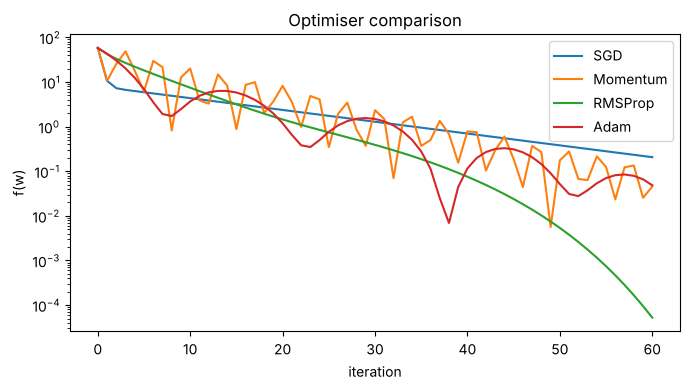

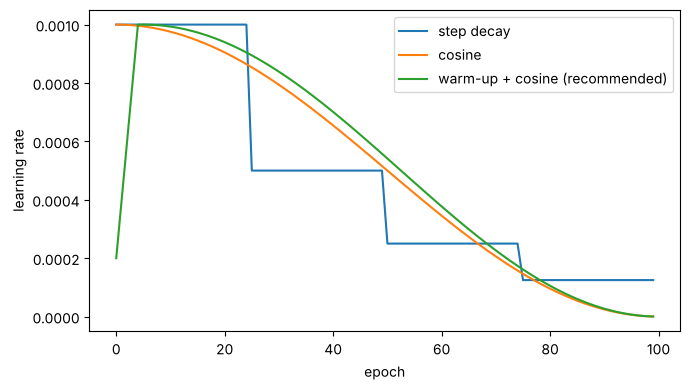

In [14]:
# --- Optimiser comparison on an ill-conditioned quadratic f(w)=0.5(w1^2 + 25 w2^2)
def grad_f(w): return np.array([w[0], 25*w[1]])
def f(w): return 0.5*(w[0]**2 + 25*w[1]**2)
def run(opt, steps=60, lr=0.03):
    w = np.array([4.0, 2.0]); v = np.zeros(2); s = np.zeros(2); m = np.zeros(2); h=[f(w)]
    for t in range(1, steps+1):
        g = grad_f(w)
        if opt=='SGD':        w -= lr*g
        elif opt=='Momentum': v = 0.9*v + g; w -= lr*v
        elif opt=='RMSProp':  s = 0.9*s + 0.1*g**2; w -= 0.1*g/(np.sqrt(s)+1e-8)
        elif opt=='Adam':
            m = 0.9*m+0.1*g; s = 0.999*s+0.001*g**2
            w -= 0.3*(m/(1-0.9**t))/(np.sqrt(s/(1-0.999**t))+1e-8)
        h.append(f(w))
    return h
plt.figure(figsize=(7,4))
for o in ['SGD','Momentum','RMSProp','Adam']:
    h = run(o); plt.semilogy(h, label=o); print(f'{o:9s} final loss after 60 steps = {h[-1]:.3e}')
print('(Illustrative only: ranking depends on the learning rate of each optimiser; adaptive methods need far less tuning on ill-conditioned problems.)')
plt.xlabel('iteration'); plt.ylabel('f(w)'); plt.legend(); plt.title('Optimiser comparison'); plt.tight_layout()
plt.savefig('figs/task12_opt.png', dpi=110); plt.show()

# --- Learning-rate schedules
ep = np.arange(100); lr0 = 1e-3
step = lr0*0.5**(ep//25)
cos  = 0.5*lr0*(1+np.cos(np.pi*ep/100))
warm = np.where(ep<5, lr0*(ep+1)/5, 0.5*lr0*(1+np.cos(np.pi*(ep-5)/95)))
plt.figure(figsize=(7,4)); plt.plot(step,label='step decay'); plt.plot(cos,label='cosine'); plt.plot(warm,label='warm-up + cosine (recommended)')
plt.xlabel('epoch'); plt.ylabel('learning rate'); plt.legend(); plt.tight_layout(); plt.savefig('figs/task12_lr_sched.png', dpi=110); plt.show()

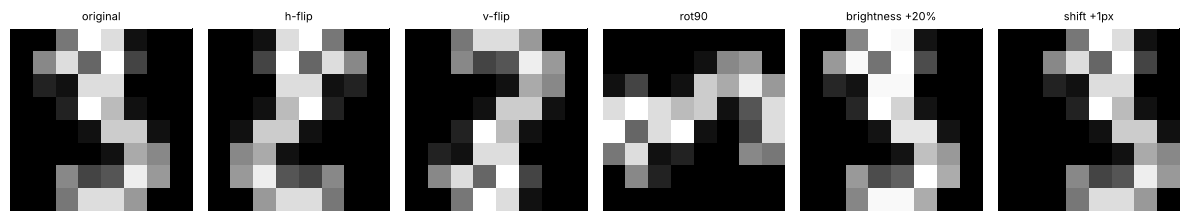

Safe: flips, 90-degree rotations, small shifts/zoom (<=10%), +/-20% brightness/contrast, slight colour jitter, Gaussian noise.
Avoid: strong hue shifts (leaf colour is diagnostic), heavy crops that remove the lesion, elastic distortion of lesion shape.


In [15]:
# --- Label-preserving augmentation (a diseased leaf stays diseased)
im = Xi[3]                       # stand-in 8x8 image
aug = {'original': im, 'h-flip': im[:, ::-1], 'v-flip': im[::-1, :], 'rot90': np.rot90(im),
       'brightness +20%': np.clip(im*1.2, 0, 1), 'shift +1px': np.roll(im, 1, axis=1)}
fig, ax = plt.subplots(1, len(aug), figsize=(12,2.2))
for a_, (k,v) in zip(ax, aug.items()): a_.imshow(v, cmap='gray'); a_.set_title(k, fontsize=8); a_.axis('off')
plt.tight_layout(); plt.savefig('figs/task12_aug.png', dpi=110); plt.show()
print('Safe: flips, 90-degree rotations, small shifts/zoom (<=10%), +/-20% brightness/contrast, slight colour jitter, Gaussian noise.')
print('Avoid: strong hue shifts (leaf colour is diagnostic), heavy crops that remove the lesion, elastic distortion of lesion shape.')

### Additional design considerations

**Optimiser comparison**

| Optimiser | Idea | Pros | Cons |
|---|---|---|---|
| Batch GD | Gradient on full data | Stable, exact gradient | Very slow/memory heavy for 500k records |
| SGD | 1 sample per update | Fast updates, escapes shallow minima | Very noisy |
| Mini-batch SGD | 32–256 samples | Best speed/stability trade-off, GPU-friendly | Needs η tuning |
| Momentum | Accumulates velocity | Damps oscillation, faster in ravines | Extra hyper-parameter β |
| RMSProp | Divides by running RMS of grads | Per-parameter adaptive η | Needs η tuning, no momentum |
| Adam | Momentum + RMSProp + bias correction | Fast default, robust | Sometimes slightly worse generalisation than tuned SGD |

**Recommendation:** Adam (lr 1e-3) with warm-up + cosine decay for both models; optionally switch to SGD+momentum for final fine-tuning.

**CNN model comparison for ~128×128 leaf images with a limited budget**

| Model | Parameters | Depth | Key idea | Suitability |
|---|---|---|---|---|
| LeNet-5 | ≈ 60 K | 5 | Conv+pool+FC | Too small for 128×128 colour leaf texture; good baseline |
| AlexNet | ≈ 61 M | 8 | ReLU, dropout, big FC layers | Heavy, FC layers wasteful |
| ResNet-18/50 | 11 M / 25.6 M | 18/50 | Residual skip connections (no vanishing gradient) | Strong, widely used with transfer learning |
| EfficientNet-B0 | ≈ 5.3 M | – | Compound scaling, MBConv | **Best accuracy per FLOP – recommended** (ResNet-18 as fallback) |

**Final recommendation:** retain only the ideas of the old feed-forward model for the numeric data (but modify and regularise it); **redesign** the system by adding a transfer-learned EfficientNet-B0 (or ResNet-18) image branch trained with Adam, warm-up cosine LR, label-preserving augmentation, dropout, L2 and early stopping.

**Reference Keras implementation (for GPU environment – not executed here):**
```python
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
tab = models.Sequential([
    layers.Input((4,)), layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(), layers.Dropout(0.2),
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)), layers.Dropout(0.2),
    layers.Dense(1)])
tab.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
aug = models.Sequential([layers.RandomFlip('horizontal_and_vertical'), layers.RandomRotation(0.05),
                         layers.RandomZoom(0.1), layers.RandomContrast(0.2)])
base = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(128,128,3))
base.trainable = False
cnn = models.Sequential([layers.Input((128,128,3)), aug, base, layers.GlobalAveragePooling2D(),
                         layers.Dropout(0.4), layers.Dense(1, activation='sigmoid')])
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
            metrics=['accuracy', tf.keras.metrics.Recall(), tf.keras.metrics.AUC()])
```